# Sensitivity analysis

In [1]:
import numpy as np
import pandas as pd

from Bio import SeqIO
from scipy.linalg import solve
from scipy import stats

import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/data"
out_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/out"
fig_path = "/Users/jdunstan/Documents/MPL project/HIV MPL paper/figures"

In [3]:
#Read consensus sequence
for record in SeqIO.parse(data_path + "/ancestor_consensus.fasta", "fasta"):
    consensus = record.seq

## MPL code

In [4]:
def MPL_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix, gamma, delta):

    ######################################              MPL algorithm               ######################################

    # x contains allele frequencies and has shape (num_mutations x number_time_points)
    # positions is a vector containing the genome position of each mutation and has length num_mutations
    # allele_numbers is a vector containing the allele present at that genome position (converted to integer) and has length num_mutations
    # time_between_samples is a vector of length number_time_points - 1, with the kth element being t_{k+1} - t_{k}
    # mutation_matrix has shape number_alleles*number_alleles, and must have a zero diagonal
    # gamma is a scalar: the regularisation parameter
    # delta is a scalar: the window size for estimating the covariance
    
    num_muts = x.shape[0]
    number_time_points = x.shape[1]


    ################### Calculate estimated integrated covariance matrix ################### 


    #Actual diagonal elements (variances)
    variances = x[:, :-1] - (x[:, :-1] ** 2) #estimated covariance only up to penultimate time point
    variances = np.maximum(variances, 0) #Ensure all variances are positive (precision limit might make them slightly negative)

    #Calculate E matrix (without multiplicative factor)
    dxdx = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        dxdx[:,:,k] = np.outer(x[:,k+1]-x[:,k], x[:,k+1]-x[:,k])

    E = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        for l in np.intersect1d(np.arange(k-delta,k+delta+1),np.arange(number_time_points-1)):
            E[:,:,k] += dxdx[:,:,l]


    #Calculate estimated covariance matrix using normalisation of non-diagonal terms
    E_diag = np.swapaxes(np.diagonal(E),0,1)
    E_prod = E_diag[:, None, :] * E_diag[None, :, :]
    var_prod = variances[:, None, :] * variances[None, :, :]
    scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
    C_est = E * scale_factor
    C_est[np.arange(num_muts),np.arange(num_muts),:] = variances[np.arange(num_muts),:] #Diagonal (variances)


    #Estimate x_ij from estimated covariances
    x_ij_est = np.zeros((num_muts,num_muts,number_time_points-1))
    for k in range(number_time_points-1):
        x_ij_est[:,:,k] = C_est[:,:,k] + np.outer(x[:,k],x[:,k]) 

    #Integrate estimated covariance matrix
    C_est_int = np.zeros((num_muts,num_muts))

    for k in range(number_time_points-2): #Non-diagonal elements
        C_est_int += time_between_samples[k]*((x_ij_est[:,:,k+1] + x_ij_est[:,:,k])/2 -
                                    (np.outer(x[:,k],x[:,k])+np.outer(x[:,k+1],x[:,k+1]))/3 - 
                                    (np.outer(x[:,k],x[:,k+1])+np.outer(x[:,k+1],x[:,k]))/6)
            
    diag = np.zeros(num_muts) #Diagonal elements
    for k in range(number_time_points-2):
        diag += time_between_samples[k]*((x[:,k+1] + x[:,k])/2 -
                                    (np.square(x[:,k+1]) + np.square(x[:,k]) + np.multiply(x[:,k+1],x[:,k]))/3)
    np.fill_diagonal(C_est_int,diag)




    ################### Calculate integrated flux vector ###################

    #Collect loci of mutations
    unique_positions = list(set(positions))
    unique_pos_idx = []
    for p in positions:
        unique_pos_idx.append((unique_positions == p).argmax())

    #Put frequencies in matrix with shape (unique_positions x num_alleles x number_time_points)
    x_matrix = np.zeros((len(unique_positions),5,number_time_points))
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        x_matrix[p,a,:] = x[i,:]

    #Calculate flux at each time point
    mu_fl_matrix = np.zeros_like(x_matrix) 
    for k in range(number_time_points): 
        mu_fl_matrix[:,:,k] = np.matmul(x_matrix[:,:,k],mutation_matrix) - (mutation_matrix.sum(axis=1))*x_matrix[:,:,k]
        
    #Piecewise linear integration of flux
    mu_fl_matrix_int = np.zeros((len(unique_positions),5)) 
    for k in range(number_time_points-1): 
        mu_fl_matrix_int += time_between_samples[k]*(mu_fl_matrix[:,:,k]+mu_fl_matrix[:,:,k+1])/2 

    #Convert flux to vector with shape (num_muts x number_time_points)
    mu_fl_vector = np.zeros(num_muts)
    for i,(p,a) in enumerate(zip(unique_pos_idx,allele_numbers)):
        mu_fl_vector[i] = mu_fl_matrix_int[p,a]



    ################### Solve for selection coefficients ###################
    s = solve(C_est_int + gamma*np.identity(num_muts), x[:,-1] - x[:,0] - mu_fl_vector, assume_a='gen')


    return s, C_est_int

In [5]:
def get_MPL_estimate(data, mutation_matrix, gamma, delta):

    #Apply the MPL method to each line individually and return dataset with fitness estimates
    dfs = []
    covariances = []

    for line in [13,14,15,16]:
        data_line = data[data['line'] == line].copy()

        #Get data in the form required for MPL
        x = data_line[np.arange(0,511,10)].astype(float).values

        time_between_samples = 10*3.5 + np.zeros(x.shape[1]-1) #in units of generations (assumed to be 3.5 generations per transfer - one per day)

        allele_numbers = data_line['new']
        allele_numbers = np.where(allele_numbers=='A',0,allele_numbers)
        allele_numbers = np.where(allele_numbers=='C',1,allele_numbers)
        allele_numbers = np.where(allele_numbers=='G',2,allele_numbers)
        allele_numbers = np.where(allele_numbers=='T',3,allele_numbers)
        allele_numbers = np.where(allele_numbers=='-',4,allele_numbers)
        allele_numbers = np.array([0 if "i" in str(new).lower() else new for new in allele_numbers])
        allele_numbers = np.array([4 if "d" in str(new).lower() else new for new in allele_numbers])
        allele_numbers = allele_numbers.astype(int)

        data_line['MPL pos'] = data_line['pos']
        if len(data_line[data_line['type']=='insertion'])>0:
            insertion_positions = np.arange(1+data_line['pos'].max(),1+data_line['pos'].max()+len(data_line[data_line['type']=='insertion'])/2).astype(int)
            if len(data_line[data_line['type']=='deletion'])>0:
                deletion_positions = np.arange(1+insertion_positions.max(),1+insertion_positions.max()+len(data_line[data_line['type']=='deletion'])/2).astype(int)
                data_line.loc[(data_line['type']=='insertion') & (data_line['details']=='consensus'),'MPL pos'] = insertion_positions
                data_line.loc[(data_line['type']=='insertion') & (data_line['details']!='consensus'),'MPL pos'] = insertion_positions
                data_line.loc[(data_line['type']=='deletion') & (data_line['details']=='consensus'),'MPL pos'] = deletion_positions
                data_line.loc[(data_line['type']=='deletion') & (data_line['details']!='consensus'),'MPL pos'] = deletion_positions
            else:
                data_line.loc[(data_line['type']=='insertion') & (data_line['details']=='consensus'),'MPL pos'] = insertion_positions
                data_line.loc[(data_line['type']=='insertion') & (data_line['details']!='consensus'),'MPL pos'] = insertion_positions
        else:
            if len(data_line[data_line['type']=='deletion'])>0:
                deletion_positions = np.arange(1+data_line['pos'].max(),1+data_line['pos'].max()+len(data_line[data_line['type']=='deletion'])/2).astype(int)
                data_line.loc[(data_line['type']=='deletion') & (data_line['details']=='consensus'),'MPL pos'] = deletion_positions
                data_line.loc[(data_line['type']=='deletion') & (data_line['details']!='consensus'),'MPL pos'] = deletion_positions
        positions = data_line['MPL pos'].values.astype(int)
        data_line = data_line.drop(columns=['MPL pos'])

        #Apply MPL to each line
        s, C_int = MPL_inference(x, positions, allele_numbers, time_between_samples, mutation_matrix, gamma, delta)
        data_line['s'] = s

        #Store covariance of non-consensus rows
        non_con_idx = data_line.reset_index().index[data_line['details'] !='consensus'].to_numpy()
        covariances.append(C_int[np.ix_(non_con_idx,non_con_idx)])

        #Normalise based on consensus mutations
        for p in data_line['pos'].unique():
            data_p = data_line[(data_line['pos']==p) & (data_line['type']=='substitution')].copy()
            consensus_s = data_p.loc[data_p['details']=='consensus','s'].values
            data_p['s'] -= consensus_s
            dfs.append(data_p[data_p['details']!='consensus']) #remove consensus rows

        for type in ['insertion','deletion']:
            data_type = data_line[(data_line['type']==type)].copy()
            s_consensus = data_type.loc[data_line['details'] == 'consensus','s']
            data_type.loc[data_line['details'] != 'consensus','s'] -= s_consensus.values
            dfs.append(data_type[data_type['details']!='consensus']) #remove consensus rows
    
    data = pd.concat(dfs)
    
    return data, covariances


## Changing sampling depth

In [6]:
#MPl parameters
gamma = 5
delta = 3
mutation_matrix = np.array(([0,1.2e-6,5.4e-6,6e-7,1e-9],[3e-6,0,5e-7,1.1e-5,1e-9],[1.5e-5,6e-8,0,1e-6,1e-9],[1.8e-6,8e-6,2e-6,0,1e-9],[1e-9,1e-9,1e-9,1e-9,0])) #from Zanini et al.

In [7]:
def add_consensus_rows(data):
    #Add consensus rows to a dataframe with only mutant rows
    consensus_rows = []

    for line in [13,14,15,16]:
        #Add in consensus allele for substitutions
        for pos in data[(data['line']==line) & (data['type']=='substitution')]['pos'].unique():
            data_line_pos = data[(data['line']==line) & (data['type']=='substitution') & (data['pos']==pos)]
            consensus_row = data_line_pos.iloc[0].copy()
            consensus_row['new'] = consensus[pos]
            consensus_row['details'] = 'consensus'
            consensus_row['Max frequency'] = 1
            consensus_row['Length'] = 51
            consensus_row.loc[np.arange(0,511,10)] = 1 - data_line_pos.loc[:,np.arange(0,511,10)].sum()
            consensus_rows.append(consensus_row.to_frame().T)

        #Add in consensus allele for insertions
        consensus_row = data[(data['line']==line) & (data['type']=='insertion')].copy()
        consensus_row['new'] = '-' 
        consensus_row['details'] = 'consensus'
        consensus_row['Max frequency'] = 1
        consensus_row['Length'] = 51
        consensus_row.loc[:,np.arange(0,511,10)] = 1 - consensus_row.loc[:,np.arange(0,511,10)]
        consensus_rows.append(consensus_row)

        #Add in consensus allele for deletions
        consensus_row = data[(data['line']==line) & (data['type']=='deletion')].copy()
        consensus_row['new'] = 'A' #Place holder for deleted sequence
        consensus_row['details'] = 'consensus'
        consensus_row['Max frequency'] = 1
        consensus_row['Length'] = 51
        consensus_row.loc[:,np.arange(0,511,10)] = 1 - consensus_row.loc[:,np.arange(0,511,10)]
        consensus_rows.append(consensus_row)


    data_with_consensus = pd.concat([data,pd.concat(consensus_rows)])
    data_with_consensus = data_with_consensus.sort_values(by=['pos','line','new']).reset_index(drop=True)
    
    return data_with_consensus


#### Changing frequency threshold

In [8]:
#Change frequency threshold to 10%
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
data = data[data['details']!='consensus'] #remove consensus rows
data_freq_10 = data[data['Max frequency']>0.1] #change threshold
data_freq_10 = add_consensus_rows(data_freq_10) #add back consensus rows
data_freq_10, _ = get_MPL_estimate(data_freq_10,  mutation_matrix, gamma, delta) #apply MPL_inference

#Combine with original 5% threshold estimates
data_freq_5 = pd.read_pickle(out_path + '/mutation_time_series_with_fitness.pkl')
combined_data_freq = pd.merge(data_freq_5[['pos','new','line','s']], data_freq_10[['pos','new','line','s']], on=['pos','new','line'], how='inner', suffixes=(' >0.05',' >0.1'))

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarn

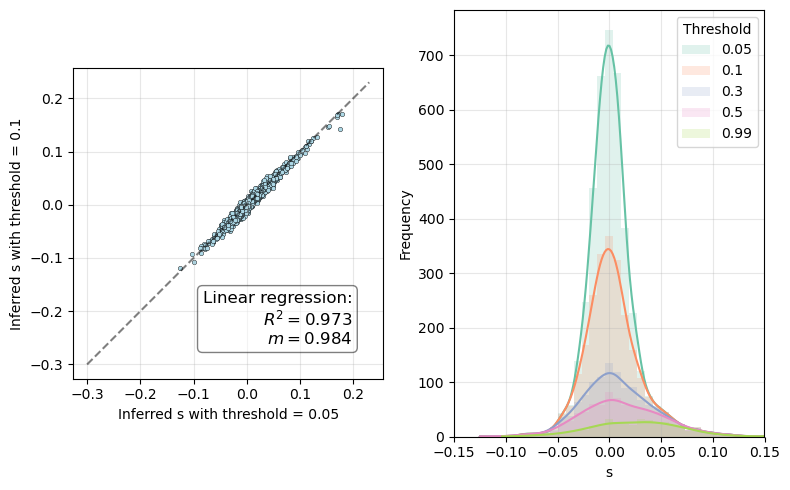

In [9]:
#Plot results
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,5))

#10% against 5% correlation
ax1.scatter(combined_data_freq['s >0.05'],combined_data_freq['s >0.1'],s=10, edgecolors='black',linewidths=0.3,c='lightblue')
m, c, r, p, std_err = stats.linregress(combined_data_freq['s >0.05'],combined_data_freq['s >0.1'])
ax1.text(0.9, 0.1, f'Linear regression:\n$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax1.transAxes, fontsize=12, verticalalignment='bottom',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax1.grid(alpha=0.3)
ax1.plot(np.linspace(-0.3,0.23,10),np.linspace(-0.3,0.23,10),'--',color='black',alpha=0.5)
ax1.set_aspect('equal', adjustable='box')
ax1.set_xlabel(f'Inferred s with threshold = 0.05')
ax1.set_ylabel(f'Inferred s with threshold = 0.1')
# ax1.set_title('Correlation of inferred selection coefficients \nwith different frequency thresholds')

#DFEs for different thresholds
colours = plt.colormaps['Set2'].colors
for i,t in enumerate([0.05,0.1,0.3,0.5,0.99]):
    data = data_freq_5[data_freq_5['Max frequency']>t]
    sns.histplot(data=data, x='s', kde=True, edgecolor=None, color=colours[i], bins=np.linspace(-0.15,0.15,40), ax=ax2, label=t, alpha=0.2)
ax2.set_ylabel('Frequency')
ax2.set_xlim(-0.15,0.15)
ax2.grid(alpha=0.3)
# ax2.set_title('Distribution of fitness effects \nat different frequency thresholds')
ax2.legend(title='Threshold')

plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_freq_threshold.pdf")
plt.show()

Robust to sampling depth, as estimates are very similar for the two different sized datasets (left). Lowering the frequency threshold seems to just add more neutral mutations to the DFE (makes sense as their trajectories don't change too much).

#### Changing length threshold

In [10]:
#Change length threshold to 20
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
data = data[data['details']!='consensus'] #remove consensus rows
data_length_20 = data[data['Length']>20] #change threshold
data_length_20 = add_consensus_rows(data_length_20) #add back consensus rows
data_length_20, _ = get_MPL_estimate(data_length_20,  mutation_matrix, gamma, delta) #apply MPL_inference

#Combine with original length 10 estimates
data_length_10 = pd.read_pickle(out_path + '/mutation_time_series_with_fitness.pkl')
combined_data_length = pd.merge(data_length_10[['pos','new','line','s']], data_length_20[['pos','new','line','s']], on=['pos','new','line'], how='inner', suffixes=(' >10',' >20'))

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_17789/3058894517.py:39: RuntimeWarn

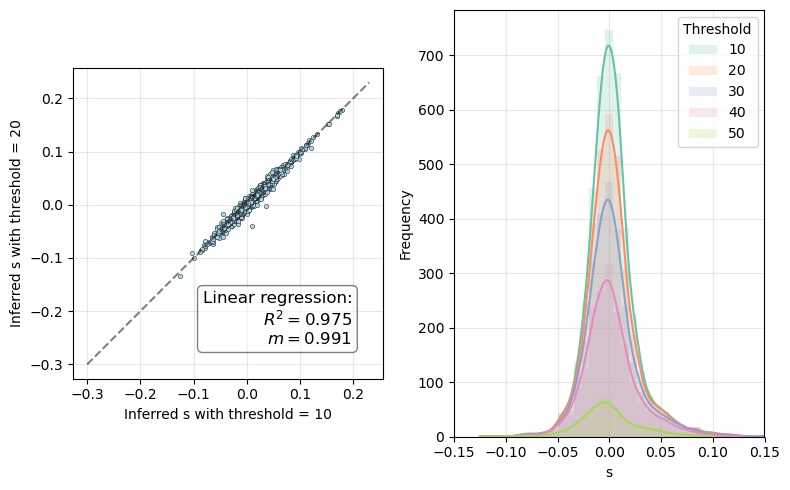

In [11]:
#Plot results
fig, (ax1,ax2) = plt.subplots(1,2,figsize=(8,5))

#20 against 10 correlation
ax1.scatter(combined_data_length['s >10'],combined_data_length['s >20'],s=10, edgecolors='black',linewidths=0.3,c='lightblue')
m, c, r, p, std_err = stats.linregress(combined_data_length['s >10'],combined_data_length['s >20'])
ax1.text(0.9, 0.1, f'Linear regression:\n$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax1.transAxes, fontsize=12, verticalalignment='bottom',horizontalalignment='right', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax1.grid(alpha=0.3)
ax1.plot(np.linspace(-0.3,0.23,10),np.linspace(-0.3,0.23,10),'--',color='black',alpha=0.5)
ax1.set_aspect('equal', adjustable='box')
ax1.set_xlabel(f'Inferred s with threshold = 10')
ax1.set_ylabel(f'Inferred s with threshold = 20')
# ax1.set_title('Correlation of inferred selection coefficients \nwith different length thresholds')

#DFEs for different thresholds
colours = plt.colormaps['Set2'].colors
for i,t in enumerate([10,20,30,40,50]):
    data = data_freq_5[data_freq_5['Length']>t]
    sns.histplot(data=data, x='s', kde=True, color=colours[i], edgecolor=None, bins=np.linspace(-0.15,0.15,40), ax=ax2, label=t, alpha=0.2)
ax2.set_ylabel('Frequency')
ax2.set_xlim(-0.15,0.15)
ax2.grid(alpha=0.3)
# ax2.set_title('Distribution of fitness effects \nat different length thresholds')
ax2.legend(title='Threshold')

plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_length_threshold.pdf")
plt.show()

Again robust to sampling depth, and as we lower the threshold, we get more mutations that are inferred to be neutral.

## Figure SI4

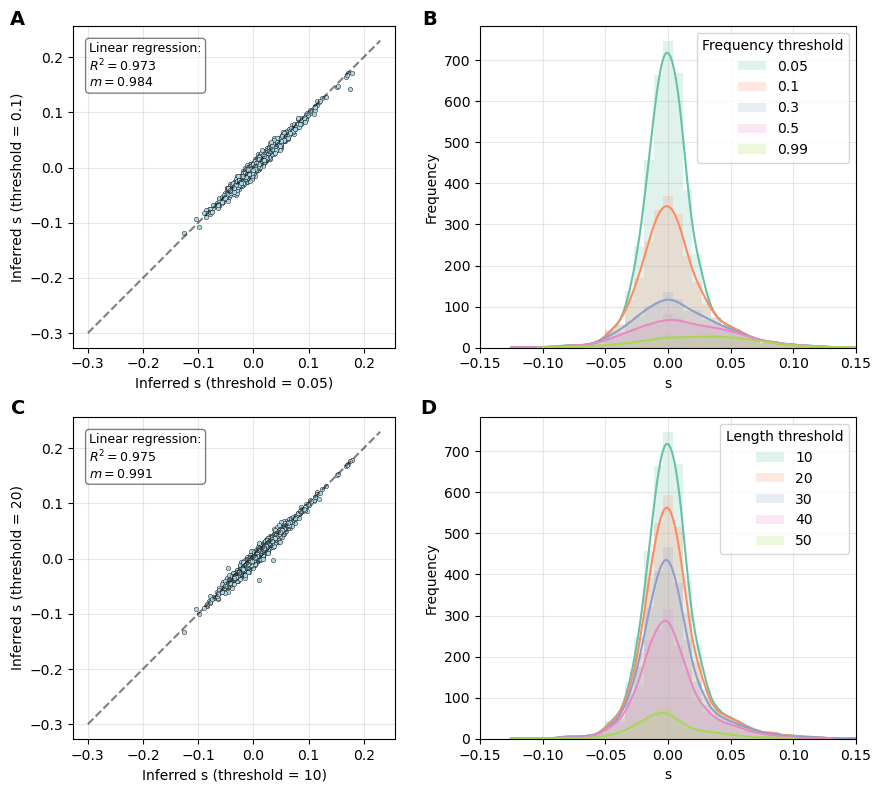

In [32]:
mosaic = [['A','B'],
          ['C','D']]
fig, ax = plt.subplot_mosaic(mosaic,figsize=(9, 8))

#10% against 5% correlation
ax['A'].scatter(combined_data_freq['s >0.05'],combined_data_freq['s >0.1'],s=10, edgecolors='black',linewidths=0.3,c='lightblue')
m, c, r, p, std_err = stats.linregress(combined_data_freq['s >0.05'],combined_data_freq['s >0.1'])
ax['A'].text(0.05, 0.95, f'Linear regression:\n$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax['A'].transAxes, fontsize=9, verticalalignment='top',horizontalalignment='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax['A'].plot(np.linspace(-0.3,0.23,10),np.linspace(-0.3,0.23,10),'--',color='black',alpha=0.5)
ax['A'].set_aspect('equal', adjustable='box')
ax['A'].set_xlabel(f'Inferred s (threshold = 0.05)')
ax['A'].set_ylabel(f'Inferred s (threshold = 0.1)')
ax['A'].text(-0.15, 1.05, 'A', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#DFEs for different thresholds
colours = plt.colormaps['Set2'].colors
for i,t in enumerate([0.05,0.1,0.3,0.5,0.99]):
    data = data_freq_5[data_freq_5['Max frequency']>t]
    sns.histplot(data=data, x='s', kde=True, edgecolor=None, color=colours[i], bins=np.linspace(-0.15,0.15,40), ax=ax['B'], label=t, alpha=0.2)
ax['B'].set_ylabel('Frequency')
ax['B'].set_xlim(-0.15,0.15)
ax['B'].legend(title='Frequency threshold')
ax['B'].text(1.13, 1.05, 'B', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#20 against 10 correlation
ax['C'].scatter(combined_data_length['s >10'],combined_data_length['s >20'],s=10, edgecolors='black',linewidths=0.3,c='lightblue')
m, c, r, p, std_err = stats.linregress(combined_data_length['s >10'],combined_data_length['s >20'])
ax['C'].text(0.05, 0.95, f'Linear regression:\n$R^2 = {r**2:.3f}$\n$m={m:.3f}$', transform=ax['C'].transAxes, fontsize=9, verticalalignment='top',horizontalalignment='left', bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
ax['C'].plot(np.linspace(-0.3,0.23,10),np.linspace(-0.3,0.23,10),'--',color='black',alpha=0.5)
ax['C'].set_aspect('equal', adjustable='box')
ax['C'].set_xlabel(f'Inferred s (threshold = 10)')
ax['C'].set_ylabel(f'Inferred s (threshold = 20)')
ax['C'].text(-0.15, -0.16, 'C', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#DFEs for different thresholds
colours = plt.colormaps['Set2'].colors
for i,t in enumerate([10,20,30,40,50]):
    data = data_freq_5[data_freq_5['Length']>t]
    sns.histplot(data=data, x='s', kde=True, color=colours[i], edgecolor=None, bins=np.linspace(-0.15,0.15,40), ax=ax['D'], label=t, alpha=0.2)
ax['D'].set_ylabel('Frequency')
ax['D'].set_xlim(-0.15,0.15)
ax['D'].legend(title='Length threshold')
ax['D'].text(1.13, -0.16, 'D', transform=ax['A'].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

#Format
for ax in [ax['A'],ax['B'],ax['C'],ax['D']]:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(fig_path + f"/Figure_SI4.pdf")
plt.show()


## Changing MPL parameters

In [35]:
#Load data from assays
assay_fitness_estimates = np.load(data_path + "/assay_fitness_estimates.npz")
assay_means = assay_fitness_estimates['means']*1.2
assay_stds = assay_fitness_estimates['stds']*1.2

#### Vary gamma

In [36]:
#MPl parameters
gamma_ = [1,5,10,100]
delta = 3
mutation_matrix = np.array(([0,1.2e-6,5.4e-6,6e-7,1e-9],[3e-6,0,5e-7,1.1e-5,1e-9],[1.5e-5,6e-8,0,1e-6,1e-9],[1.8e-6,8e-6,2e-6,0,1e-9],[1e-9,1e-9,1e-9,1e-9,0])) #from Zanini et al.

#Run MPL (~6 minutes)
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
covariances_gamma = []
for gamma in gamma_:
    data_gamma,covariances = get_MPL_estimate(data, mutation_matrix, gamma, delta) 
    data[f's: gamma={gamma}'] = data_gamma['s']
    covariances_gamma.append(covariances)

data = data[data['details']!='consensus']

#Store mean and std estimates
MPL_fitness_estimates_gamma = np.zeros((len(gamma_),4,52))
MPL_std_gamma = np.zeros((len(gamma_),4,52))

for i, gamma in enumerate(gamma_):
    covariances = covariances_gamma[i]
    
    for j, line in enumerate([13,14,15,16]):
        data_line = data[data['line']==line]
        cov_x = covariances[j]
        cov_s = (np.linalg.inv(cov_x + gamma*np.identity(cov_x.shape[0])))/data_line['Mean pop size'].mean()
        
        for k, gen in enumerate(np.arange(0,511,10)):
            MPL_fitness_estimates_gamma[i,j,k] = np.sum(data_line[f's: gamma={gamma}']*data_line[gen])
            MPL_std_gamma[i,j,k] = np.sqrt(data_line[gen].values.dot(cov_s).dot(data_line[gen].values))
            

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarn

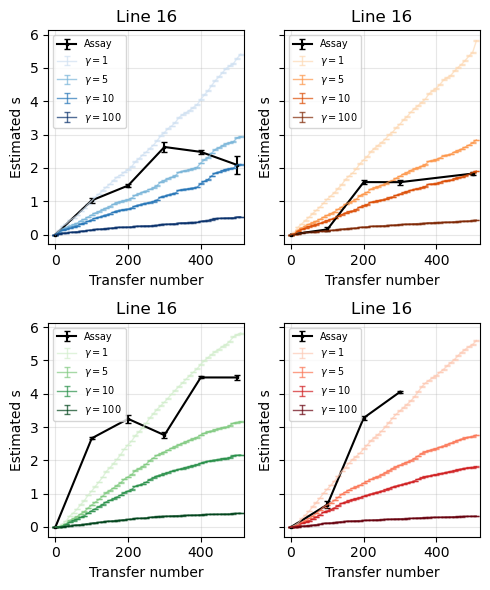

In [37]:
#Plot results
fig, axes = plt.subplots(2,2,figsize=(5,6),sharey=True)
axes = axes.flatten()
cmaps = ['Blues','Oranges','Greens','Reds']

for j, ax in enumerate(axes):
    #Plot assay estimates
    assay_means_plot = np.concat(([0],assay_means[j,:]))
    assay_stds_plot = np.concat(([0],assay_stds[j,:]))

    mask = ~np.isnan(assay_means_plot)
    ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
    
    #Plot MPL estimates
    cmap = plt.get_cmap(cmaps[j])
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(gamma_))]
    for i, gamma in enumerate(gamma_):
        ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_gamma[i,j,:],yerr=MPL_std_gamma[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'$\gamma=${gamma}')
    
    #Format
    ax.set_xlim(-20,520)
    ax.grid(alpha=0.3)
    ax.set_ylabel('Estimated s')
    ax.set_xlabel('Transfer number')
    ax.set_title(f'Line {i+13}')
    ax.legend(loc='upper left',fontsize=7)

plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_gamma.pdf")
plt.show()

In [38]:
for i,gamma in enumerate(gamma_):
    MPL_estimates = MPL_fitness_estimates_gamma[i][:,::10][:,1:]
    mask = ~np.isnan(assay_means.flatten())
    rmse = np.sqrt(np.mean(np.square(MPL_estimates.flatten()[mask]-assay_means.flatten()[mask])))
    print(f'For gamma = {gamma}, RMSE = {rmse}')


For gamma = 1, RMSE = 1.494676646541151
For gamma = 5, RMSE = 1.1899247054547255
For gamma = 10, RMSE = 1.548545671886126
For gamma = 100, RMSE = 2.4162055947386465


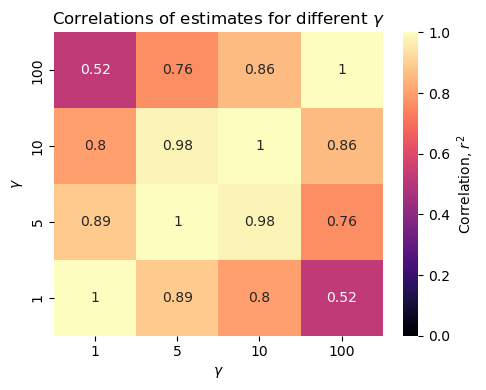

In [39]:
#Correlation test for gamma
correlations = np.zeros((len(gamma_),len(gamma_)))
for i,gamma_i in enumerate(gamma_):
    for j,gamma_j in enumerate(gamma_):
        _,_,r,_,_= stats.linregress(data[f's: gamma={gamma_i}'],data[f's: gamma={gamma_j}'])
        correlations[i,j] = r**2

fig, ax = plt.subplots(1,1,figsize=(5,4))
ax = sns.heatmap(correlations, vmin=0, vmax=1, annot=True, cmap='magma', xticklabels=gamma_, yticklabels=gamma_)
ax.invert_yaxis()
ax.set_xlabel('$\gamma$')
ax.set_ylabel('$\gamma$')
cbar = ax.collections[0].colorbar
cbar.set_label("Correlation, $r^2$")
plt.title('Correlations of estimates for different $\gamma$')
plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_gamma_correlation_test.pdf")
plt.show()

Above $\gamma = 5$, the correlations are all very high, implying gamma is just acting to reduce the overall magnitude, and the noise is reduced sufficiently by $\gamma = 5$.

#### Vary delta

In [40]:
#MPl parameters
gamma = 5
delta_ = [1,3,5,10]
mutation_matrix = np.array(([0,1.2e-6,5.4e-6,6e-7,1e-9],[3e-6,0,5e-7,1.1e-5,1e-9],[1.5e-5,6e-8,0,1e-6,1e-9],[1.8e-6,8e-6,2e-6,0,1e-9],[1e-9,1e-9,1e-9,1e-9,0])) #from Zanini et al.

#Run MPL (~7 minutes)
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
covariances_delta = []
for delta in delta_:
    data_delta,covariances = get_MPL_estimate(data, mutation_matrix, gamma, delta) 
    data[f's: delta={delta}'] = data_delta['s']
    covariances_delta.append(covariances)

data = data[data['details']!='consensus']

#Store mean and std estimates
MPL_fitness_estimates_delta = np.zeros((len(delta_),4,52))
MPL_std_delta = np.zeros((len(delta_),4,52))

for i, delta in enumerate(delta_):
    covariances = covariances_delta[i]
    
    for j, line in enumerate([13,14,15,16]):
        data_line = data[data['line']==line]
        cov_x = covariances[j]
        cov_s = (np.linalg.inv(cov_x + gamma*np.identity(cov_x.shape[0])))/data_line['Mean pop size'].mean()
        
        for k, gen in enumerate(np.arange(0,511,10)):
            MPL_fitness_estimates_delta[i,j,k] = np.sum(data_line[f's: delta={delta}']*data_line[gen])
            MPL_std_delta[i,j,k] = np.sqrt(data_line[gen].values.dot(cov_s).dot(data_line[gen].values))
            

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarn

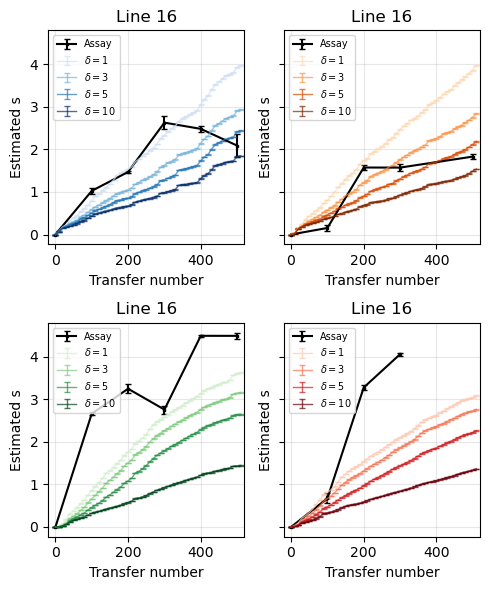

In [41]:
#Plot results
fig, axes = plt.subplots(2,2,figsize=(5,6),sharey=True)
axes = axes.flatten()
cmaps = ['Blues','Oranges','Greens','Reds']

for j, ax in enumerate(axes):
    #Plot assay estimates
    assay_means_plot = np.concat(([0],assay_means[j,:]))
    assay_stds_plot = np.concat(([0],assay_stds[j,:]))

    mask = ~np.isnan(assay_means_plot)
    ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
    
    #Plot MPL estimates
    cmap = plt.get_cmap(cmaps[j])
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(delta_))]
    for i, delta in enumerate(delta_):
        ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_delta[i,j,:],yerr=MPL_std_delta[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'$\delta=${delta}')
    
    #Format
    ax.set_xlim(-20,520)
    ax.grid(alpha=0.3)
    ax.set_ylabel('Estimated s')
    ax.set_xlabel('Transfer number')
    ax.set_title(f'Line {i+13}')
    ax.legend(loc='upper left',fontsize=7)

plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_delta.pdf")
plt.show()

In [42]:
for i,delta in enumerate(delta_):
    MPL_estimates = MPL_fitness_estimates_delta[i][:,::10][:,1:]
    mask = ~np.isnan(assay_means.flatten())
    rmse = np.sqrt(np.mean(np.square(MPL_estimates.flatten()[mask]-assay_means.flatten()[mask])))
    print(f'For delta = {delta}, RMSE = {rmse}')


For delta = 1, RMSE = 1.1920365729313116
For delta = 3, RMSE = 1.1899247054547255
For delta = 5, RMSE = 1.4290613843527589
For delta = 10, RMSE = 1.8793184310002558


#### Vary mutation rates

In [43]:
#MPl parameters
gamma = 5
delta = 3
mutation_matrix = np.array(([0,1.2e-6,5.4e-6,6e-7,1e-9],[3e-6,0,5e-7,1.1e-5,1e-9],[1.5e-5,6e-8,0,1e-6,1e-9],[1.8e-6,8e-6,2e-6,0,1e-9],[1e-9,1e-9,1e-9,1e-9,0])) #from Zanini et al.
mutation_scaling = [0.5,1,2]

#Run MPL (~5 minutes)
data = pd.read_pickle(out_path + f'/mutation_time_series.pkl')
covariances_mut_scaling = []
for scale in mutation_scaling:
    data_mut_scaling,covariances = get_MPL_estimate(data, scale*mutation_matrix, gamma, delta) 
    data[f's: mut_scale={scale}'] = data_mut_scaling['s']
    covariances_mut_scaling.append(covariances)

data = data[data['details']!='consensus']

#Store mean and std estimates
MPL_fitness_estimates_mut = np.zeros((len(mutation_scaling),4,52))
MPL_std_mut = np.zeros((len(mutation_scaling),4,52))

for i, scale in enumerate(mutation_scaling):
    covariances = covariances_mut_scaling[i]
    
    for j, line in enumerate([13,14,15,16]):
        data_line = data[data['line']==line]
        cov_x = covariances[j]
        cov_s = (np.linalg.inv(cov_x + gamma*np.identity(cov_x.shape[0])))/data_line['Mean pop size'].mean()
        
        for k, gen in enumerate(np.arange(0,511,10)):
            MPL_fitness_estimates_mut[i,j,k] = np.sum(data_line[f's: mut_scale={scale}']*data_line[gen])
            MPL_std_mut[i,j,k] = np.sqrt(data_line[gen].values.dot(cov_s).dot(data_line[gen].values))
            

/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarning: invalid value encountered in divide
  scale_factor = np.where(E_prod>0, np.sqrt(var_prod/E_prod),1) #Only apply normalisation if estimated covariances are not zero (might be if no change in frequencies)
/var/folders/8v/24szc0p12jq_4176tdqdxc2h0000gp/T/ipykernel_50899/3058894517.py:39: RuntimeWarn

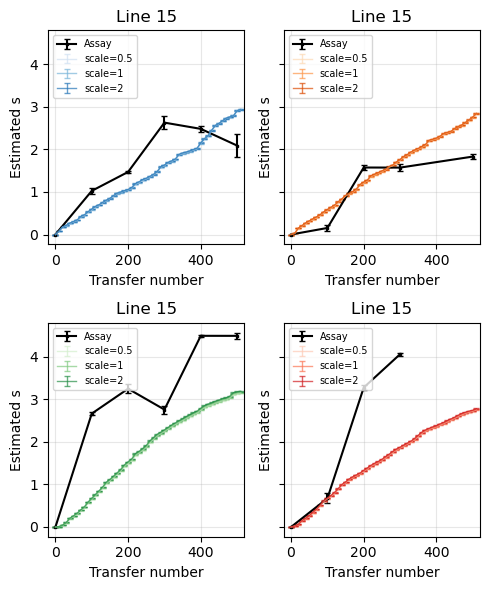

In [44]:
#Plot results
fig, axes = plt.subplots(2,2,figsize=(5,6),sharey=True)
axes = axes.flatten()
cmaps = ['Blues','Oranges','Greens','Reds']

for j, ax in enumerate(axes):
    #Plot assay estimates
    assay_means_plot = np.concat(([0],assay_means[j,:]))
    assay_stds_plot = np.concat(([0],assay_stds[j,:]))

    mask = ~np.isnan(assay_means_plot)
    ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
     
    #Plot MPL estimates
    cmap = plt.get_cmap(cmaps[j])
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(delta_))]
    for i, scale in enumerate(mutation_scaling):
        ax.errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_mut[i,j,:],yerr=MPL_std_mut[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'scale={scale}')
    
    #Format
    ax.set_xlim(-20,520)
    ax.grid(alpha=0.3)
    ax.set_ylabel('Estimated s')
    ax.set_xlabel('Transfer number')
    ax.set_title(f'Line {i+13}')
    ax.legend(loc='upper left',fontsize=7)

plt.tight_layout()
plt.savefig(fig_path + f"/sensitivity_mut_scaling.pdf")
plt.show()

In [45]:
for i,scale in enumerate(mutation_scaling):
    MPL_estimates = MPL_fitness_estimates_mut[i][:,::10][:,1:]
    mask = ~np.isnan(assay_means.flatten())
    rmse = np.sqrt(np.mean(np.square(MPL_estimates.flatten()[mask]-assay_means.flatten()[mask])))
    print(f'For scale = {scale}, RMSE = {rmse}')

For scale = 0.5, RMSE = 1.195830157131869
For scale = 1, RMSE = 1.1899247054547255
For scale = 2, RMSE = 1.1781728853843094


## Figure SI11

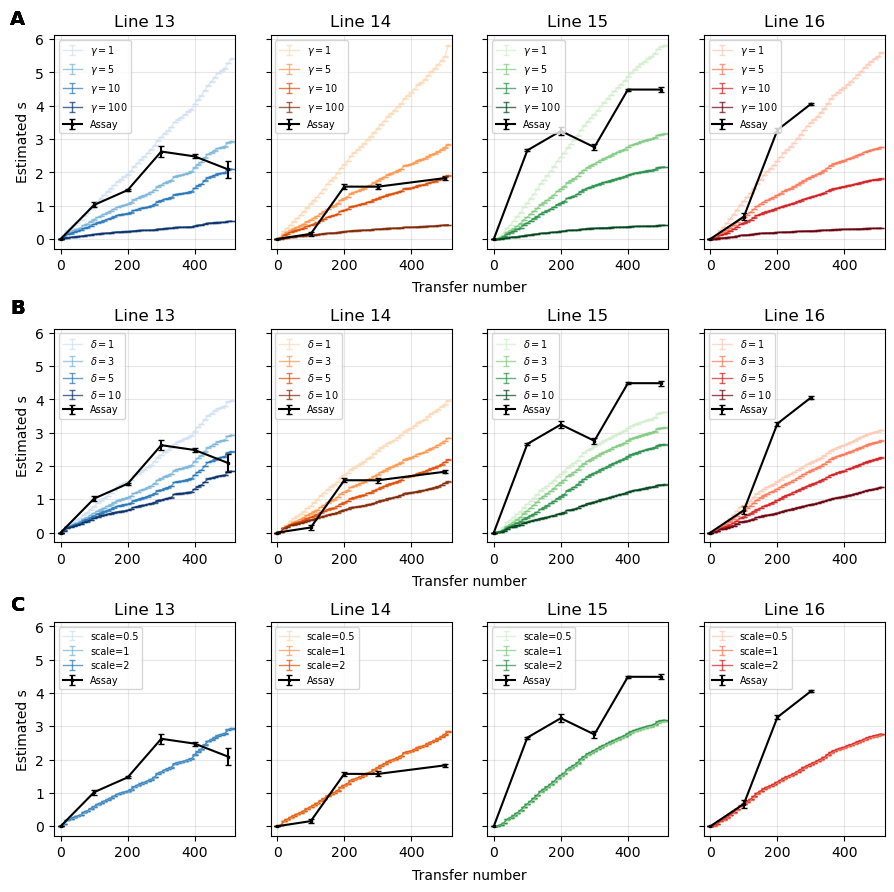

In [70]:
fig, axes = plt.subplots(3,4,figsize=(9,9),sharey=True)
cmaps = ['Blues','Oranges','Greens','Reds']

for j in range(4):
    cmap = plt.get_cmap(cmaps[j])

    #Changing gamma
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(gamma_))]
    for i, gamma in enumerate(gamma_):
        axes[0,j].errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_gamma[i,j,:],yerr=MPL_std_gamma[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'$\gamma=${gamma}')
    axes[0,0].text(-0.16, 1.12, 'A', transform=axes[0,0].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')

    #Changing delta
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(delta_))]
    for i, delta in enumerate(delta_):
        axes[1,j].errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_delta[i,j,:],yerr=MPL_std_delta[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'$\delta=${delta}')
    axes[1,0].text(-0.16, -0.23, 'B', transform=axes[0,0].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')
    
    #Changing mutation scaling
    colours = [cmap(p) for p in np.linspace(0.2, 1, len(delta_))]
    for i, scale in enumerate(mutation_scaling):
        axes[2,j].errorbar(np.array(np.arange(0,511,10)),MPL_fitness_estimates_mut[i,j,:],yerr=MPL_std_mut[i,j,:],marker='',capsize=2, markersize=0, linewidth=1,color=colours[i],alpha=0.7,label=f'scale={scale}')
    axes[2,0].text(-0.16, -1.62, 'C', transform=axes[0,0].transAxes, fontsize=14, fontweight='bold', va='top', ha='right')
    

#Plot assay estimates
for i in range(3):
    for j, ax in enumerate(axes[i,:]):
        assay_means_plot = np.concat(([0],assay_means[j,:]))
        assay_stds_plot = np.concat(([0],assay_stds[j,:]))
        mask = ~np.isnan(assay_means_plot)
        ax.errorbar(np.array([0,100,200,300,400,500])[mask],assay_means_plot[mask],yerr=assay_stds_plot[mask],marker='s',markersize=2,capsize=2,color='black',label='Assay')
    

#Format
for ax in axes.flatten():
    ax.set_xlim(-20,520)
    ax.grid(alpha=0.3)


for i in range(3):
    axes[i,1].set_xlabel('Transfer number')
    axes[i,1].xaxis.set_label_coords(1.1, -0.15)
    axes[i,0].set_ylabel('Estimated s')
    
    for j in range(4): 
        axes[i,j].set_title(f'Line {j+13}')
        axes[i,j].legend(loc='upper left',fontsize=7)

plt.tight_layout()
plt.savefig(fig_path + f"/Figure_SI11.pdf")
plt.show()